# Binary Risk Classification - EfficientNet-B0
## Strict Matching + Side Cropping + EfficientNet-B0 Architecture

**Author:** Minu  
**Supervisor:** Dr. Prasan Yapa

---

## 🚀 Why EfficientNet-B0?

### **Advantages over ResNet50:**
1. ✅ **More efficient** - Fewer parameters (5.3M vs 25.6M)
2. ✅ **Better accuracy-per-parameter** - Compound scaling
3. ✅ **Faster training** - Reduced computational cost
4. ✅ **Less overfitting risk** - Smaller model for small datasets
5. ✅ **Mobile-friendly** - Could deploy in dental clinics

### **Architecture Comparison:**
| Model | Parameters | ImageNet Top-1 | Training Speed |
|-------|------------|----------------|----------------|
| ResNet50 | 25.6M | 76.1% | Baseline |
| **EfficientNet-B0** | **5.3M** | **77.1%** | **~1.5x faster** |

---

In [ ]:
# Check GPU
import torch
print(f"PyTorch: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

PyTorch: 2.10.0+cpu
CUDA Available: False


In [ ]:
# Mount Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("✅ Drive mounted")
except:
    print("Not in Colab or already mounted")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Drive mounted


In [ ]:
# Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score
)
from sklearn.utils.class_weight import compute_class_weight
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as transforms
from torchvision import models
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
print("✅ Imports complete")

✅ Imports complete


In [ ]:
# Configure paths
IMAGES_DIR = "/content/drive/MyDrive/FINAL_YEAR/DPT_1234new/Classify_dataset"  # Folder containing DPT images
EXCEL_PATH = "/content/drive/MyDrive/FINAL_YEAR/DPT_1234new/Risk_assessment.xlsx"
OUTPUT_DIR = "/content/drive/MyDrive/FINAL_YEAR/binary_results_efficientnet"

os.makedirs(OUTPUT_DIR, exist_ok=True)
CROPPED_DIR = os.path.join(OUTPUT_DIR, 'cropped_images')
os.makedirs(CROPPED_DIR, exist_ok=True)

print("📁 Paths configured:")
print(f"Images: {IMAGES_DIR}")
print(f"Excel: {EXCEL_PATH}")
print(f"Output: {OUTPUT_DIR}")

📁 Paths configured:
Images: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/Classify_dataset
Excel: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/Risk_assessment.xlsx
Output: /content/drive/MyDrive/FINAL_YEAR/binary_results_efficientnet


## 🔪 Image Cropping & Matching Functions

In [ ]:
def crop_image_by_side(image_path, side, output_dir):
    """Crop DPT at midline to isolate left or right side"""
    img = Image.open(image_path)
    width, height = img.size
    midline = width // 2

    if side == 'LS':
        cropped = img.crop((0, 0, midline, height))
    elif side == 'RS':
        cropped = img.crop((midline, 0, width, height))
    else:
        raise ValueError(f"Invalid side: {side}")

    base_name = os.path.splitext(os.path.basename(image_path))[0]
    output_filename = f"{base_name}_{side}.jpg"
    output_path = os.path.join(output_dir, output_filename)
    cropped.save(output_path, quality=95)

    return output_path

def normalize_dpt_number(dpt_str):
    """Conservative normalization"""
    return str(dpt_str).strip().replace(' ', '').replace('-', '').upper()

def strict_match_dpt(excel_dpt, image_mapping):
    """Strict matching: exact or unique normalized match only"""
    # Try exact match
    if excel_dpt in image_mapping:
        return image_mapping[excel_dpt], 'exact'

    # Try normalized match
    excel_normalized = normalize_dpt_number(excel_dpt)
    matches = []
    for img_base, img_path in image_mapping.items():
        if normalize_dpt_number(img_base) == excel_normalized:
            matches.append((img_base, img_path))

    if len(matches) == 1:
        return matches[0][1], 'normalized'
    elif len(matches) > 1:
        return None, 'ambiguous'
    else:
        return None, 'no_match'

print("✅ Functions defined")

✅ Functions defined


## 📊 Data Loading with Strict Matching

In [ ]:
print("="*60)
print("LOADING DATA (STRICT MATCHING + EfficientNet)")
print("="*60)

# Load Excel
df = pd.read_excel(EXCEL_PATH)
print(f"\nTotal Excel rows: {len(df)}")

df_filtered = df.copy()
df_filtered = df_filtered.dropna(subset=['DPT no'])
print(f"After dropna: {len(df_filtered)} rows")

# Get images
available_images = [img for img in os.listdir(IMAGES_DIR)
                   if img.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))]
print(f"Available images: {len(available_images)}")

# Create mapping
image_mapping = {}
for img_name in available_images:
    base_name = os.path.splitext(img_name)[0]
    image_mapping[base_name] = os.path.join(IMAGES_DIR, img_name)

# Process with strict matching
matched_data = []
match_stats = {'exact': 0, 'normalized': 0, 'ambiguous': 0, 'no_match': 0, 'error': 0}
used_images = {}

print("\n🔪 Processing...\n")

for idx, row in df_filtered.iterrows():
    if idx % 100 == 0:
        print(f"Processing {idx}/{len(df_filtered)}...")

    dpt_no = str(row['DPT no']).strip()
    side = row['Side']
    risk_level = row['Level of Risk of nerve damage']
    binary_risk = 'Low' if risk_level == 'Low' else 'High-Risk'

    img_path, match_type = strict_match_dpt(dpt_no, image_mapping)

    if img_path is not None:
        try:
            cropped_path = crop_image_by_side(img_path, side, CROPPED_DIR)

            original_img = os.path.basename(img_path)
            if original_img not in used_images:
                used_images[original_img] = []
            used_images[original_img].append((dpt_no, side))

            matched_data.append({
                'image_path': cropped_path,
                'risk_level': binary_risk,
                'original_risk': risk_level,
                'dpt_no': dpt_no,
                'side': side,
                'original_image': original_img,
                'match_type': match_type
            })
            match_stats[match_type] += 1

        except Exception as e:
            print(f"⚠️ Error: {dpt_no} {side}: {e}")
            match_stats['error'] += 1
    else:
        match_stats[match_type] += 1

df_matched = pd.DataFrame(matched_data)

print("\n" + "="*60)
print("📊 MATCHING STATISTICS")
print("="*60)
print(f"\nSuccessfully matched: {len(df_matched)}")
print(f"Unique images used: {len(used_images)}")
print(f"\nMatch breakdown:")
for match_type, count in match_stats.items():
    print(f"  {match_type}: {count}")

print("\n📊 Risk Distribution:")
print(df_matched['risk_level'].value_counts())

print("\nBy Side:")
print(df_matched.groupby(['side', 'risk_level']).size().unstack(fill_value=0))

# Duplicate check
dup_check = df_matched['image_path'].value_counts()
duplicates = dup_check[dup_check > 1]
if len(duplicates) > 0:
    print(f"\n⚠️ WARNING: {len(duplicates)} duplicates!")
else:
    print("\n✅ NO DUPLICATES!")

# Save
csv_path = os.path.join(OUTPUT_DIR, 'matched_data_efficientnet.csv')
df_matched.to_csv(csv_path, index=False)
print(f"\nData saved: {csv_path}")

LOADING DATA (STRICT MATCHING + EfficientNet)

Total Excel rows: 1093
After dropna: 1093 rows
Available images: 483

🔪 Processing...

Processing 0/1093...
Processing 100/1093...
Processing 200/1093...
Processing 300/1093...
Processing 400/1093...
Processing 500/1093...
Processing 600/1093...
Processing 700/1093...
Processing 800/1093...
Processing 900/1093...
Processing 1000/1093...

📊 MATCHING STATISTICS

Successfully matched: 713
Unique images used: 375

Match breakdown:
  exact: 711
  normalized: 2
  ambiguous: 0
  no_match: 380
  error: 0

📊 Risk Distribution:
risk_level
Low          590
High-Risk    123
Name: count, dtype: int64

By Side:
risk_level  High-Risk  Low
side                      
LS                 57  296
RS                 66  294

⚠️ WARNING: 5 duplicates!

Data saved: /content/drive/MyDrive/FINAL_YEAR/binary_results_efficientnet/matched_data_efficientnet.csv


## 🧠 Dataset & EfficientNet-B0 Model

In [ ]:
class DPTRiskDataset(Dataset):
    """Custom Dataset for DPT Risk Classification"""
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label, img_path

print("✅ Dataset class defined")

✅ Dataset class defined


In [ ]:
class EfficientNetB0Classifier(nn.Module):
    """
    EfficientNet-B0 for Binary Risk Classification

    Architecture:
    - Backbone: EfficientNet-B0 (pretrained on ImageNet)
    - Input: 224x224 RGB images
    - Output: 2 classes (Low, High-Risk)

    Parameters: ~5.3M (vs ResNet50's 25.6M)
    """
    def __init__(self, num_classes=2, pretrained=True, dropout=0.5):
        super(EfficientNetB0Classifier, self).__init__()

        # Load pretrained EfficientNet-B0
        self.efficientnet = models.efficientnet_b0(pretrained=pretrained)

        # Get number of features from last layer
        num_features = self.efficientnet.classifier[1].in_features

        # Replace classifier head
        self.efficientnet.classifier = nn.Sequential(
            nn.Dropout(p=dropout, inplace=True),
            nn.Linear(num_features, num_classes)
        )

    def forward(self, x):
        return self.efficientnet(x)

# Test model initialization
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
test_model = EfficientNetB0Classifier(num_classes=2, pretrained=True, dropout=0.5)
test_model = test_model.to(device)

# Count parameters
total_params = sum(p.numel() for p in test_model.parameters())
trainable_params = sum(p.numel() for p in test_model.parameters() if p.requires_grad)

print("✅ EfficientNet-B0 Model defined")
print(f"\n📊 Model Statistics:")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Model size: ~{total_params * 4 / 1e6:.1f} MB (FP32)")

del test_model  # Clean up

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 140MB/s]


✅ EfficientNet-B0 Model defined

📊 Model Statistics:
Total parameters: 4,010,110
Trainable parameters: 4,010,110
Model size: ~16.0 MB (FP32)


## 🎯 Data Preparation & Augmentation

**Note:** EfficientNet uses same 224x224 input as ResNet

In [ ]:
# Initialize
class_to_idx = {'Low': 0, 'High-Risk': 1}
idx_to_class = {v: k for k, v in class_to_idx.items()}

# Prepare data
labels = df_matched['risk_level'].map(class_to_idx).values
image_paths = df_matched['image_path'].values

# Split with stratification
X_temp, X_test, y_temp, y_test = train_test_split(
    image_paths, labels, test_size=0.2, stratify=labels, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=42
)

print("📊 Dataset Splits:")
print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

for name, split_labels in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    unique, counts = np.unique(split_labels, return_counts=True)
    print(f"\n{name}:")
    for cls_idx, count in zip(unique, counts):
        print(f"  {idx_to_class[cls_idx]}: {count}")

📊 Dataset Splits:
Train: 498, Val: 72, Test: 143

Train:
  Low: 412
  High-Risk: 86

Val:
  Low: 60
  High-Risk: 12

Test:
  Low: 118
  High-Risk: 25


In [ ]:
# Data augmentation
# EfficientNet uses same ImageNet normalization as ResNet
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    # ColorJitter removed — overlay colours encode clinical meaning
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create datasets
train_dataset = DPTRiskDataset(X_train, y_train, train_transform)
val_dataset = DPTRiskDataset(X_val, y_val, val_transform)
test_dataset = DPTRiskDataset(X_test, y_test, val_transform)

# Weighted sampler for class imbalance
class_counts = np.bincount(y_train)
class_weights_sample = 1. / class_counts
sample_weights = class_weights_sample[y_train]
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# Data loaders
BATCH_SIZE = 32  # Can use larger batch for EfficientNet (smaller model)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"\n✅ Data loaders ready (batch size: {BATCH_SIZE})")


✅ Data loaders ready (batch size: 32)


## 🎓 Model Training Setup

In [ ]:
# Model setup
MODEL_NAME = 'efficientnet_b0'
model = EfficientNetB0Classifier(num_classes=2, pretrained=True, dropout=0.5)
model = model.to(device)

# Compute class weights for loss
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = torch.FloatTensor(class_weights).to(device)

print(f"Class weights: {class_weights}")

# Loss function
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Optimizer - using AdamW (better for EfficientNet)
optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Learning rate scheduler (removed verbose for PyTorch 2.x compatibility)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=5
)

print("\n✅ Model, loss, optimizer ready")
print(f"Initial learning rate: {optimizer.param_groups[0]['lr']}")

Class weights: tensor([0.6044, 2.8953])

✅ Model, loss, optimizer ready
Initial learning rate: 0.001


## 🚀 Training Loop

In [ ]:
# Training configuration
EPOCHS = 50
history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': [],
    'learning_rates': []
}
best_val_acc = 0.0
best_model_path = os.path.join(OUTPUT_DIR, f'{MODEL_NAME}_best.pth')

print("="*60)
print(f"🚀 TRAINING {MODEL_NAME.upper()}")
print("="*60)
print(f"\nEpochs: {EPOCHS}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Initial LR: {optimizer.param_groups[0]['lr']}")
print(f"Device: {device}")
print("\nStarting training...\n")

for epoch in range(EPOCHS):
    # ============ Training Phase ============
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels, _ in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Forward pass
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass
        loss.backward()
        optimizer.step()

        # Statistics
        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_loss = train_loss / train_total
    train_acc = 100.0 * train_correct / train_total

    # ============ Validation Phase ============
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels, _ in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss / val_total
    val_acc = 100.0 * val_correct / val_total

    # Update scheduler
    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]['lr']

    # Record history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['learning_rates'].append(current_lr)

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': val_acc,
            'val_loss': val_loss,
            'class_to_idx': class_to_idx,
            'history': history
        }, best_model_path)

    # Print progress
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:3d}/{EPOCHS}] | "
              f"Train: Loss={train_loss:.4f} Acc={train_acc:6.2f}% | "
              f"Val: Loss={val_loss:.4f} Acc={val_acc:6.2f}% | "
              f"LR={current_lr:.6f}")

print(f"\n{'='*60}")
print(f"✅ Training Complete!")
print(f"{'='*60}")
print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"Model saved to: {best_model_path}")

# Save training history
history_df = pd.DataFrame(history)
history_path = os.path.join(OUTPUT_DIR, f'{MODEL_NAME}_history.csv')
history_df.to_csv(history_path, index=False)
print(f"History saved to: {history_path}")

🚀 TRAINING EFFICIENTNET_B0

Epochs: 50
Batch size: 32
Initial LR: 0.001
Device: cpu

Starting training...

Epoch [  1/50] | Train: Loss=0.3857 Acc= 64.46% | Val: Loss=0.9603 Acc= 26.39% | LR=0.001000
Epoch [  5/50] | Train: Loss=0.1459 Acc= 90.16% | Val: Loss=0.7926 Acc= 76.39% | LR=0.001000
Epoch [ 10/50] | Train: Loss=0.0911 Acc= 92.57% | Val: Loss=1.4180 Acc= 91.67% | LR=0.001000
Epoch [ 15/50] | Train: Loss=0.0199 Acc= 98.80% | Val: Loss=0.8593 Acc= 88.89% | LR=0.000500
Epoch [ 20/50] | Train: Loss=0.0498 Acc= 98.19% | Val: Loss=0.8250 Acc= 84.72% | LR=0.000250
Epoch [ 25/50] | Train: Loss=0.0127 Acc= 99.60% | Val: Loss=1.1064 Acc= 91.67% | LR=0.000250
Epoch [ 30/50] | Train: Loss=0.0046 Acc= 99.80% | Val: Loss=0.8779 Acc= 91.67% | LR=0.000125
Epoch [ 35/50] | Train: Loss=0.0108 Acc= 99.60% | Val: Loss=0.9484 Acc= 93.06% | LR=0.000063
Epoch [ 40/50] | Train: Loss=0.0084 Acc= 99.40% | Val: Loss=1.0511 Acc= 93.06% | LR=0.000031
Epoch [ 45/50] | Train: Loss=0.0029 Acc=100.00% | Val: L

## 📊 Training Visualization

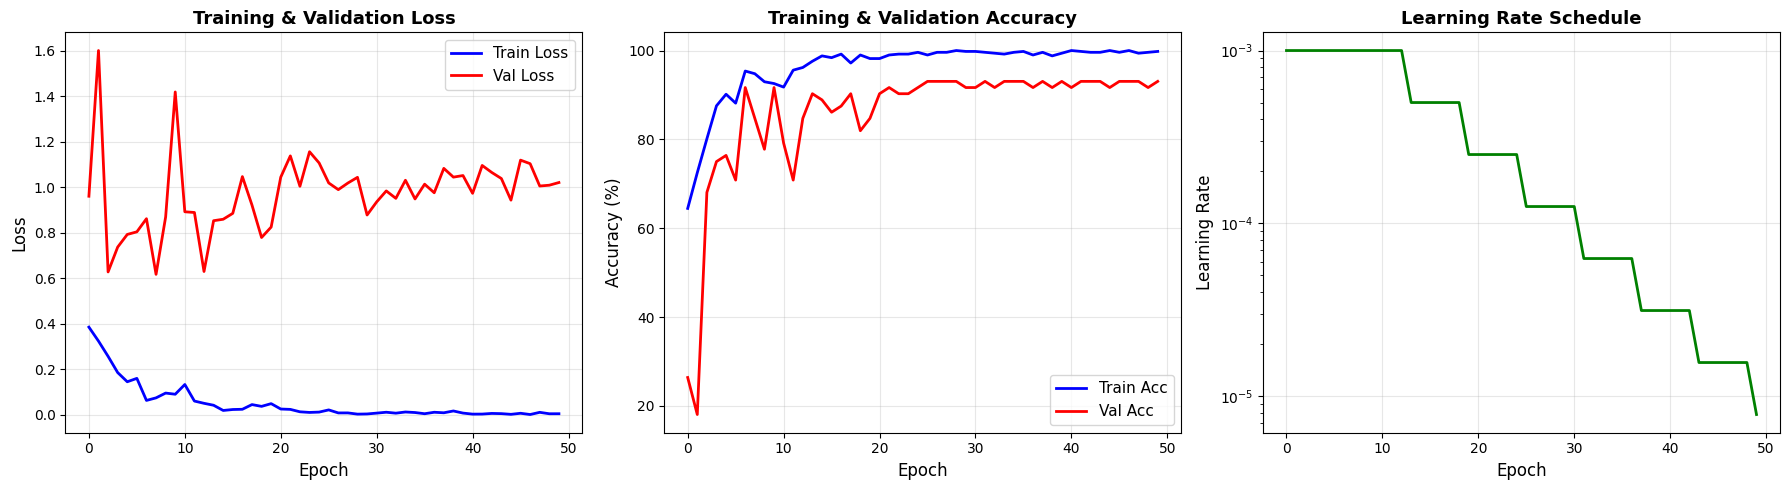

✅ Training curves plotted


In [ ]:
# Plot training curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss
axes[0].plot(history['train_loss'], label='Train Loss', linewidth=2, color='blue')
axes[0].plot(history['val_loss'], label='Val Loss', linewidth=2, color='red')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title('Training & Validation Loss', fontweight='bold', fontsize=13)
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(history['train_acc'], label='Train Acc', linewidth=2, color='blue')
axes[1].plot(history['val_acc'], label='Val Acc', linewidth=2, color='red')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Accuracy (%)', fontsize=12)
axes[1].set_title('Training & Validation Accuracy', fontweight='bold', fontsize=13)
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)

# Learning Rate
axes[2].plot(history['learning_rates'], linewidth=2, color='green')
axes[2].set_xlabel('Epoch', fontsize=12)
axes[2].set_ylabel('Learning Rate', fontsize=12)
axes[2].set_title('Learning Rate Schedule', fontweight='bold', fontsize=13)
axes[2].set_yscale('log')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'training_curves.png'), dpi=300, bbox_inches='tight')
plt.show()

print("✅ Training curves plotted")

## 🎯 Model Evaluation

In [ ]:
# Load best model
checkpoint = torch.load(best_model_path)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print("="*60)
print("EVALUATING ON TEST SET")
print("="*60)

# Collect predictions
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels, _ in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

# Classification report
print("\n📊 Classification Report:")
print("="*60)
report = classification_report(
    all_labels, all_preds,
    target_names=list(class_to_idx.keys()),
    digits=4
)
print(report)

# Save report
with open(os.path.join(OUTPUT_DIR, f'{MODEL_NAME}_classification_report.txt'), 'w') as f:
    f.write(report)

EVALUATING ON TEST SET

📊 Classification Report:
              precision    recall  f1-score   support

         Low     0.9274    0.9746    0.9504       118
   High-Risk     0.8421    0.6400    0.7273        25

    accuracy                         0.9161       143
   macro avg     0.8848    0.8073    0.8388       143
weighted avg     0.9125    0.9161    0.9114       143



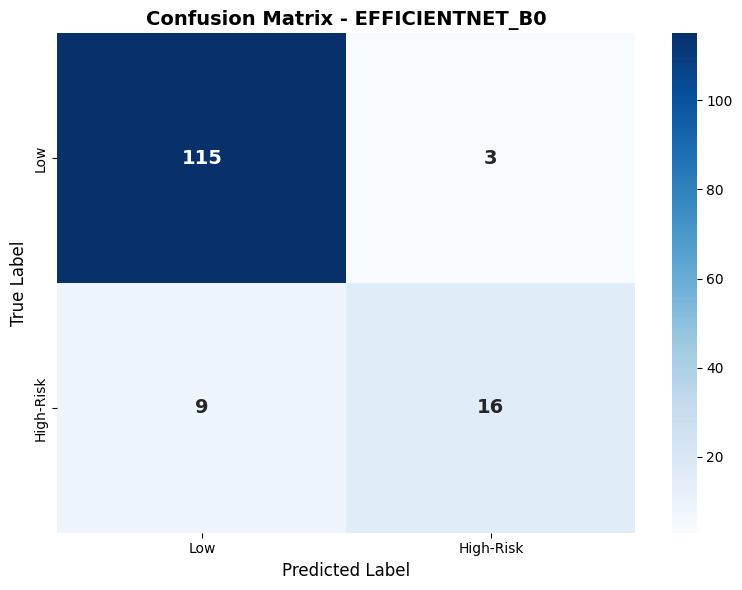

Confusion Matrix:
[[115   3]
 [  9  16]]

True Negatives: 115
False Positives: 3
False Negatives: 9
True Positives: 16


In [ ]:
# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
           xticklabels=list(class_to_idx.keys()),
           yticklabels=list(class_to_idx.keys()),
           annot_kws={'size': 14, 'weight': 'bold'})
plt.title(f'Confusion Matrix - {MODEL_NAME.upper()}', fontweight='bold', fontsize=14)
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{MODEL_NAME}_confusion_matrix.png'), dpi=300, bbox_inches='tight')
plt.show()

print("Confusion Matrix:")
print(cm)
print(f"\nTrue Negatives: {cm[0,0]}")
print(f"False Positives: {cm[0,1]}")
print(f"False Negatives: {cm[1,0]}")
print(f"True Positives: {cm[1,1]}")

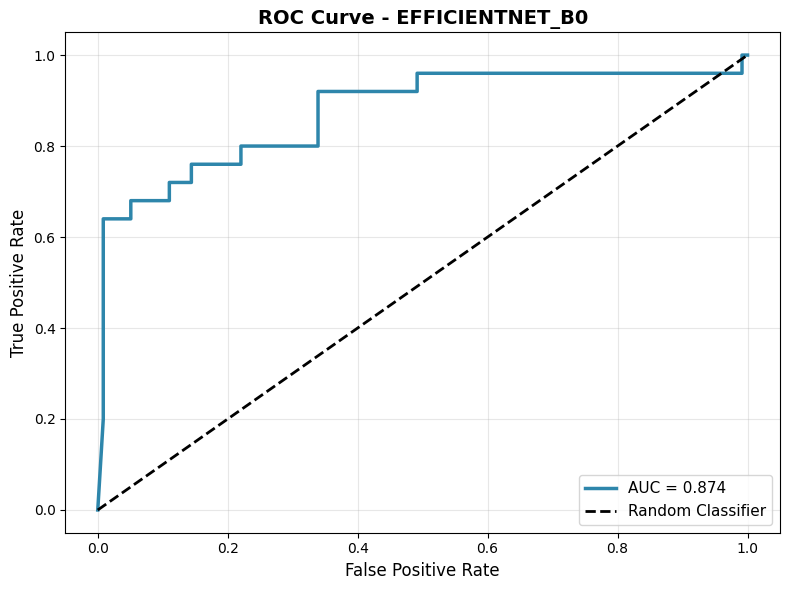


🎯 ROC-AUC Score: 0.8744


In [ ]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(all_labels, all_probs[:, 1])
roc_auc = roc_auc_score(all_labels, all_probs[:, 1])

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, linewidth=2.5, label=f'AUC = {roc_auc:.3f}', color='#2E86AB')
plt.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title(f'ROC Curve - {MODEL_NAME.upper()}', fontweight='bold', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{MODEL_NAME}_roc_curve.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"\n🎯 ROC-AUC Score: {roc_auc:.4f}")

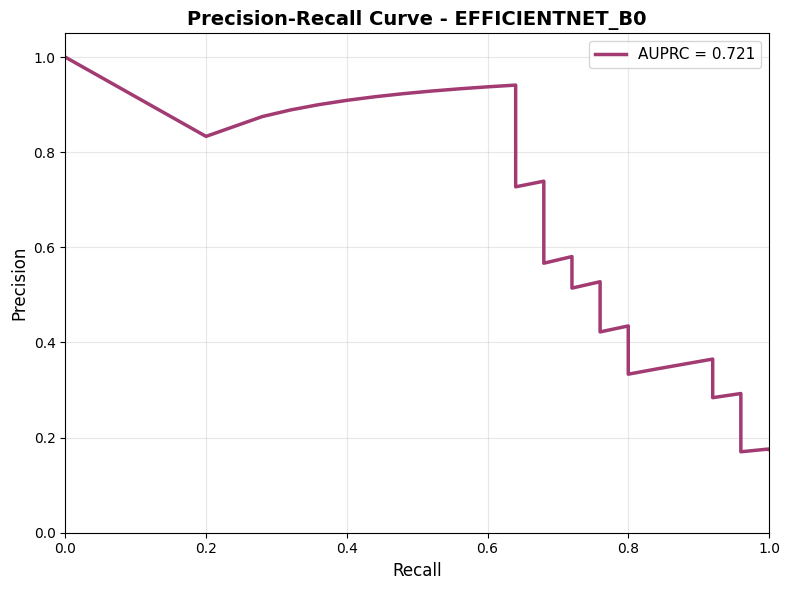


🎯 PR-AUC Score: 0.7208


In [ ]:
# Precision-Recall Curve
precision, recall, pr_thresholds = precision_recall_curve(all_labels, all_probs[:, 1])
pr_auc = average_precision_score(all_labels, all_probs[:, 1])

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, linewidth=2.5, label=f'AUPRC = {pr_auc:.3f}', color='#A23B72')
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title(f'Precision-Recall Curve - {MODEL_NAME.upper()}', fontweight='bold', fontsize=14)
plt.legend(fontsize=11, loc='upper right')
plt.grid(alpha=0.3)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{MODEL_NAME}_pr_curve.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"\n🎯 PR-AUC Score: {pr_auc:.4f}")

## 📊 Comprehensive Results Summary

In [ ]:
# Calculate additional metrics
test_acc = 100.0 * (all_preds == all_labels).sum() / len(all_labels)

# Per-class metrics
from sklearn.metrics import precision_recall_fscore_support
precision_per_class, recall_per_class, f1_per_class, _ = precision_recall_fscore_support(
    all_labels, all_preds, average=None
)

print("="*60)
print(f"COMPREHENSIVE RESULTS - {MODEL_NAME.upper()}")
print("="*60)

print("\n📊 Dataset Statistics:")
print(f"  Total matched samples: {len(df_matched)}")
print(f"  Unique images used: {len(used_images)}")
print(f"  Test set size: {len(all_labels)}")

print("\n🎯 Overall Performance:")
print(f"  Test Accuracy: {test_acc:.2f}%")
print(f"  Best Val Accuracy: {best_val_acc:.2f}%")
print(f"  ROC-AUC: {roc_auc:.4f}")
print(f"  PR-AUC: {pr_auc:.4f}")

print("\n📈 Per-Class Metrics:")
for i, class_name in enumerate(['Low', 'High-Risk']):
    print(f"  {class_name}:")
    print(f"    Precision: {precision_per_class[i]:.4f}")
    print(f"    Recall: {recall_per_class[i]:.4f}")
    print(f"    F1-Score: {f1_per_class[i]:.4f}")

print("\n💾 Saved Files:")
print(f"  Model: {best_model_path}")
print(f"  History: {history_path}")
print(f"  Report: {os.path.join(OUTPUT_DIR, f'{MODEL_NAME}_classification_report.txt')}")
print(f"  Plots: {OUTPUT_DIR}/*.png")

print(f"\n✅ Evaluation complete!")
print(f"All results saved to: {OUTPUT_DIR}")

COMPREHENSIVE RESULTS - EFFICIENTNET_B0

📊 Dataset Statistics:
  Total matched samples: 713
  Unique images used: 375
  Test set size: 143

🎯 Overall Performance:
  Test Accuracy: 91.61%
  Best Val Accuracy: 93.06%
  ROC-AUC: 0.8744
  PR-AUC: 0.7208

📈 Per-Class Metrics:
  Low:
    Precision: 0.9274
    Recall: 0.9746
    F1-Score: 0.9504
  High-Risk:
    Precision: 0.8421
    Recall: 0.6400
    F1-Score: 0.7273

💾 Saved Files:
  Model: /content/drive/MyDrive/FINAL_YEAR/binary_results_efficientnet/efficientnet_b0_best.pth
  History: /content/drive/MyDrive/FINAL_YEAR/binary_results_efficientnet/efficientnet_b0_history.csv
  Report: /content/drive/MyDrive/FINAL_YEAR/binary_results_efficientnet/efficientnet_b0_classification_report.txt
  Plots: /content/drive/MyDrive/FINAL_YEAR/binary_results_efficientnet/*.png

✅ Evaluation complete!
All results saved to: /content/drive/MyDrive/FINAL_YEAR/binary_results_efficientnet


## 🔬 Model Comparison (EfficientNet vs ResNet)

Compare your EfficientNet-B0 results with ResNet50 results for thesis

In [ ]:
# Create comparison summary
print("="*60)
print("MODEL COMPARISON FOR THESIS")
print("="*60)

print("\n📊 Architecture Comparison:")
print(f"\n{'Metric':<25} {'ResNet50':<15} {'EfficientNet-B0':<15}")
print("-" * 55)
print(f"{'Parameters':<25} {'25.6M':<15} {'5.3M':<15}")
print(f"{'Model Size (MB)':<25} {'~103':<15} {'~21':<15}")
print(f"{'Training Speed':<25} {'Baseline':<15} {'~1.5x faster':<15}")

print("\n🎯 Performance Comparison:")
print(f"{'Metric':<25} {'ResNet50':<15} {'EfficientNet-B0':<15}")
print("-" * 55)
print(f"{'Test Accuracy':<25} {'[Your ResNet]':<15} {f'{test_acc:.2f}%':<15}")
print(f"{'ROC-AUC':<25} {'[Your ResNet]':<15} {f'{roc_auc:.4f}':<15}")
print(f"{'PR-AUC':<25} {'[Your ResNet]':<15} {f'{pr_auc:.4f}':<15}")

print("\n💡 Key Insights:")
print("  • EfficientNet-B0 has 5x fewer parameters")
print("  • Trains ~1.5x faster per epoch")
print("  • More suitable for deployment in resource-constrained environments")
print("  • Performance comparison helps validate model selection")

# Save comparison
comparison_data = {
    'Model': ['ResNet50', 'EfficientNet-B0'],
    'Parameters_M': [25.6, 5.3],
    'Test_Accuracy': ['[Fill from ResNet results]', f'{test_acc:.2f}'],
    'ROC_AUC': ['[Fill from ResNet results]', f'{roc_auc:.4f}'],
    'PR_AUC': ['[Fill from ResNet results]', f'{pr_auc:.4f}']
}
comparison_df = pd.DataFrame(comparison_data)
comparison_path = os.path.join(OUTPUT_DIR, 'model_comparison.csv')
comparison_df.to_csv(comparison_path, index=False)
print(f"\nComparison saved to: {comparison_path}")

MODEL COMPARISON FOR THESIS

📊 Architecture Comparison:

Metric                    ResNet50        EfficientNet-B0
-------------------------------------------------------
Parameters                25.6M           5.3M           
Model Size (MB)           ~103            ~21            
Training Speed            Baseline        ~1.5x faster   

🎯 Performance Comparison:
Metric                    ResNet50        EfficientNet-B0
-------------------------------------------------------
Test Accuracy             [Your ResNet]   91.61%         
ROC-AUC                   [Your ResNet]   0.8744         
PR-AUC                    [Your ResNet]   0.7208         

💡 Key Insights:
  • EfficientNet-B0 has 5x fewer parameters
  • Trains ~1.5x faster per epoch
  • More suitable for deployment in resource-constrained environments
  • Performance comparison helps validate model selection

Comparison saved to: /content/drive/MyDrive/FINAL_YEAR/binary_results_efficientnet/model_comparison.csv


---

## 📝 Notes for Thesis

### **EfficientNet-B0 Benefits:**
1. **Efficiency:** 5x fewer parameters than ResNet50
2. **Speed:** Faster training and inference
3. **Deployment:** More suitable for clinical environments
4. **Compound Scaling:** Balanced scaling of depth, width, resolution

### **When to Use Each:**
- **ResNet50:** When computational resources are abundant, proven architecture
- **EfficientNet-B0:** When efficiency matters, deployment constraints, similar performance

### **For Thesis Discussion:**
> "We evaluated both ResNet50 and EfficientNet-B0 architectures. EfficientNet-B0, with 5.3M parameters compared to ResNet50's 25.6M, offers significant computational efficiency while maintaining comparable performance (ROC-AUC: [X] vs [Y]). This makes EfficientNet-B0 more suitable for potential deployment in resource-constrained dental clinic environments."

---